In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from datetime import datetime
import os
#from sklearn.ensemble import IsolationForest
#from sklearn.preprocessing import RobustScaler
#from sklearn.preprocessing import OneHotEncoder

In [4]:
#Lettura file dati mergiati ch4-bufale e robot, selezionando solo colonne che ci servono per questo momento.

mandria_path = './dati_bufale/dati_grezzi_agosto_luglio/Dataset_CH4/Bufale_Rinna/Luglio/merged_buffalo_sniffer_AMS_detrended.csv'
mandria = pd.read_csv(mandria_path, usecols = ['timestamp', 'CH4', 'CO2', 'Numero animale', 'milking_number', 'Ora inizio', 'Durata (mm:ss)', 'Milking_end'])

mandria['Numero animale'] = mandria['Numero animale'].apply(lambda x: int(x))
mandria['milking_number'] = mandria['milking_number'].apply(lambda x: int(x))


mandria_ch4 = mandria[['timestamp', 'CH4', 'Numero animale', 'milking_number']]

In [5]:
mandria_ch4.tail()

,timestamp,CH4,Numero animale,milking_number
890806,2024-07-23 12:42:31.873548,34.221017,233733,1740
890807,2024-07-23 12:42:32.875246,15.721147,233733,1740
890808,2024-07-23 12:45:00.238828,-13.759690,245591,1741
890809,2024-07-23 12:45:01.241485,-17.059559,245591,1741
890810,2024-07-23 12:45:02.244261,-18.459429,245591,1741


In [6]:
#check
mungiture = list(set(mandria_ch4['milking_number']))
print(len(mungiture))
animals = list(set(mandria_ch4['Numero animale']))
print(len(animals))

1741
36


Milking mean is:  256.5683539549994
Milking median is:  88.9695172777373
Milking std. deviation is 448.38
treshold is std x3:  1345.1399999999999


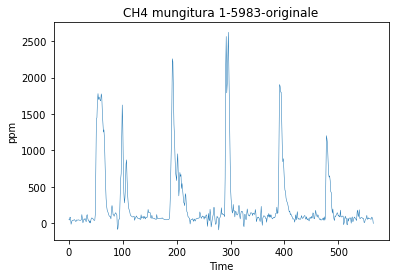

Milking mean is:  190.91307100482675
Milking median is:  98.73534422655868
Milking std. deviation is 288.13
treshold is std x3:  864.39


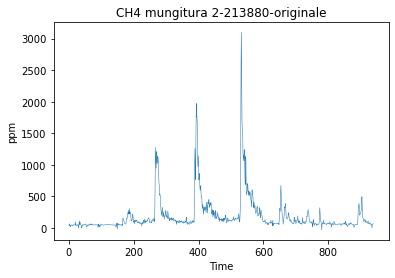

Milking mean is:  62.50374722079289
Milking median is:  63.145499555041766
Milking std. deviation is 24.13
treshold is std x3:  72.39


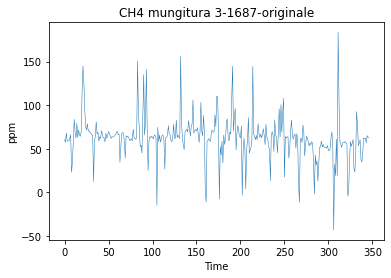

Milking mean is:  134.30891932982715
Milking median is:  84.9494691479317
Milking std. deviation is 143.65
treshold is std x3:  430.95000000000005


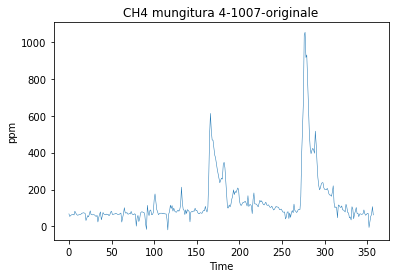

Milking mean is:  73.4734949618766
Milking median is:  62.44496525401525
Milking std. deviation is 55.52
treshold is std x3:  166.56


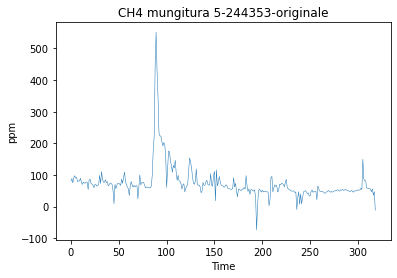

Milking mean is:  70.3281275244705
Milking median is:  61.67168289994697
Milking std. deviation is 49.4
treshold is std x3:  148.2


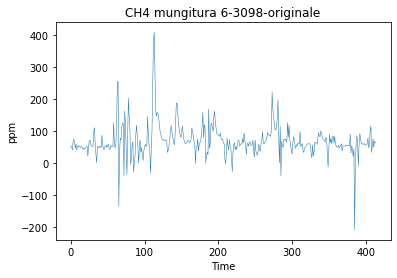

Milking mean is:  91.6493403133196
Milking median is:  62.02982405557236
Milking std. deviation is 110.56
treshold is std x3:  331.68


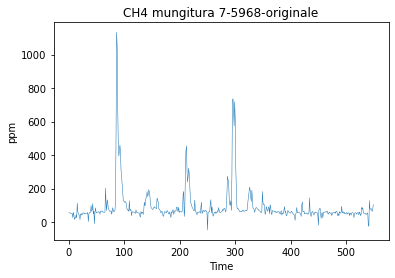

Milking mean is:  54.18020161579267
Milking median is:  55.540376895904174
Milking std. deviation is 23.96
treshold is std x3:  71.88


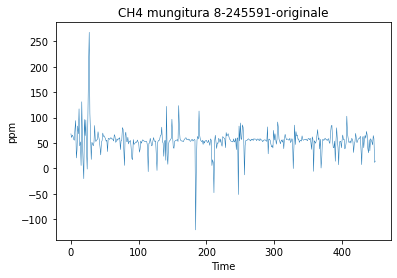

Milking mean is:  61.478595696800646
Milking median is:  59.33032621738741
Milking std. deviation is 15.88
treshold is std x3:  47.64


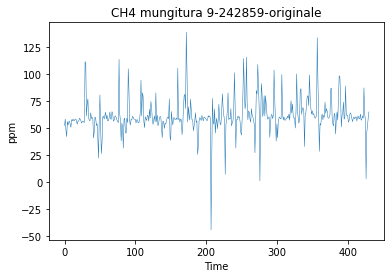

Milking mean is:  57.06593087969706
Milking median is:  57.70697868265138
Milking std. deviation is 19.62
treshold is std x3:  58.86


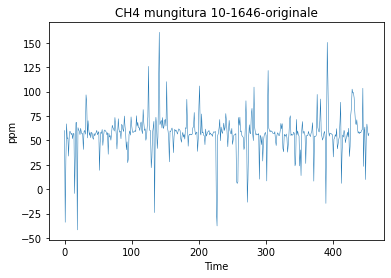

Milking mean is:  58.56299979452812
Milking median is:  58.01094827554131
Milking std. deviation is 15.19
treshold is std x3:  45.57


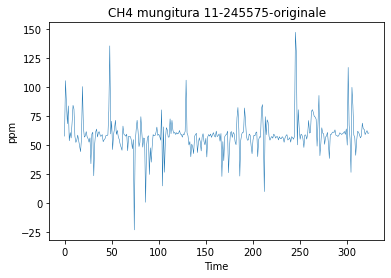

Milking mean is:  60.06676720203167
Milking median is:  59.74281519422459
Milking std. deviation is 31.54
treshold is std x3:  94.62


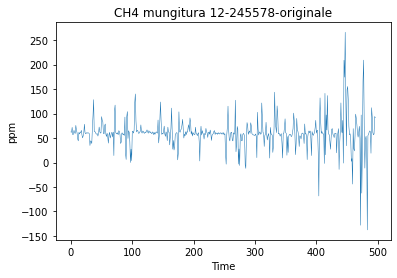

Milking mean is:  61.72740114640285
Milking median is:  62.859358228146334
Milking std. deviation is 23.54
treshold is std x3:  70.62


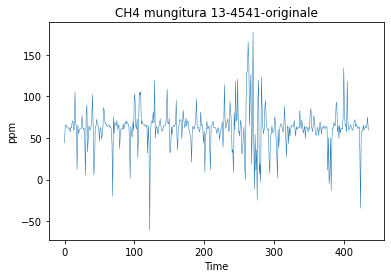

Milking mean is:  78.16434048031152
Milking median is:  72.23731430676511
Milking std. deviation is 37.49
treshold is std x3:  112.47


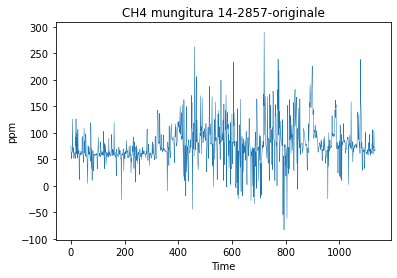

Milking mean is:  116.55598253194275
Milking median is:  73.76454697019648
Milking std. deviation is 161.85
treshold is std x3:  485.54999999999995


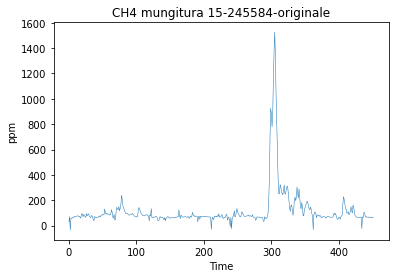

Milking mean is:  72.90692396478853
Milking median is:  69.96049291311192
Milking std. deviation is 20.68
treshold is std x3:  62.04


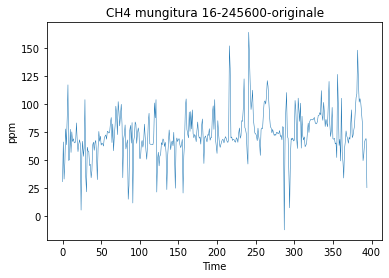

Milking mean is:  75.4172432424052
Milking median is:  73.1348053021795
Milking std. deviation is 21.13
treshold is std x3:  63.39


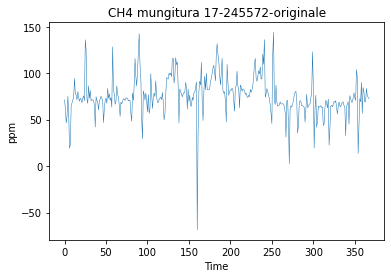

Milking mean is:  103.00781489578117
Milking median is:  77.04457597449841
Milking std. deviation is 99.9
treshold is std x3:  299.70000000000005


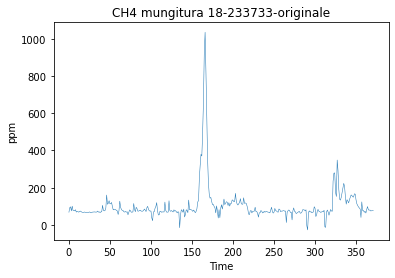

Milking mean is:  96.64042365931527
Milking median is:  75.33054927524941
Milking std. deviation is 72.86
treshold is std x3:  218.57999999999998


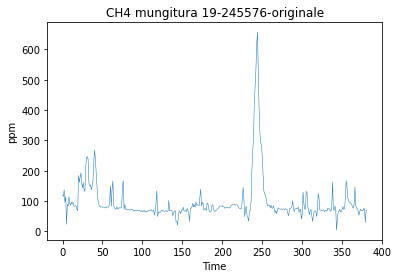

Milking mean is:  69.8224120631858
Milking median is:  70.58171700167128
Milking std. deviation is 16.95
treshold is std x3:  50.849999999999994


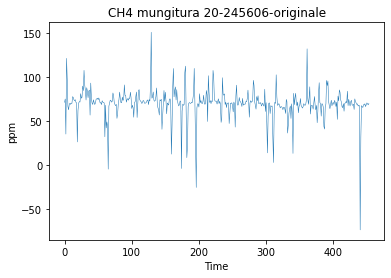

Milking mean is:  67.58599788467473
Milking median is:  67.74057514464182
Milking std. deviation is 13.92
treshold is std x3:  41.76


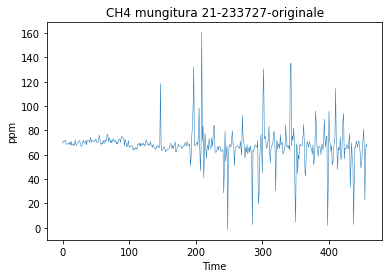

Milking mean is:  62.25451850031544
Milking median is:  65.3752384041957
Milking std. deviation is 71.87
treshold is std x3:  215.61


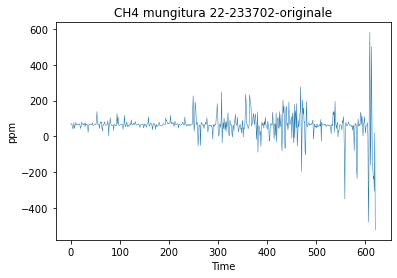

Milking mean is:  62.42439167682314
Milking median is:  62.25997327225963
Milking std. deviation is 20.93
treshold is std x3:  62.79


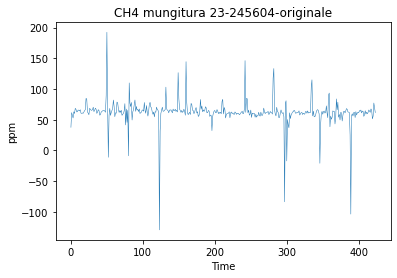

Milking mean is:  64.81367409470134
Milking median is:  64.33206309078167
Milking std. deviation is 17.01
treshold is std x3:  51.03


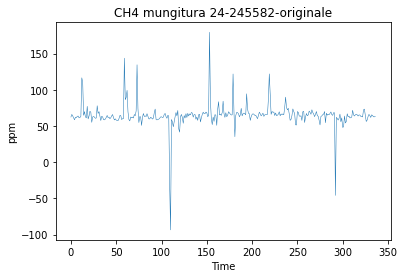

Milking mean is:  77.51297519808374
Milking median is:  67.58512015432323
Milking std. deviation is 35.96
treshold is std x3:  107.88


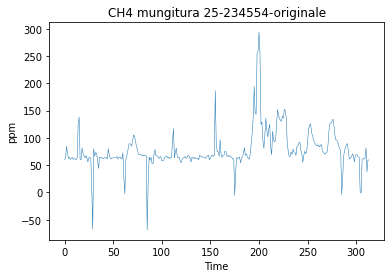

Milking mean is:  -95.77937655570106
Milking median is:  -95.81289138418825
Milking std. deviation is 23.47
treshold is std x3:  70.41


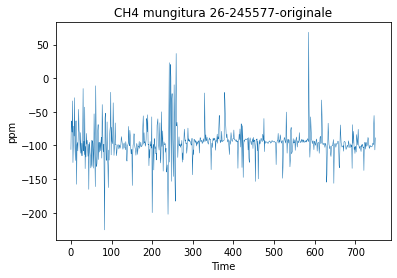

Milking mean is:  -84.53603745897169
Milking median is:  -85.63547513219345
Milking std. deviation is 24.72
treshold is std x3:  74.16


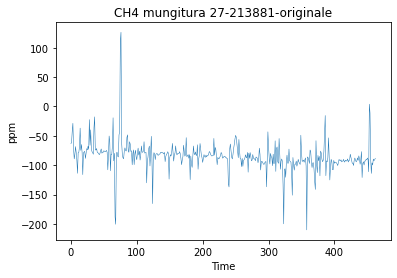

Milking mean is:  -95.62109134336092
Milking median is:  -95.43163590063901
Milking std. deviation is 17.49
treshold is std x3:  52.47


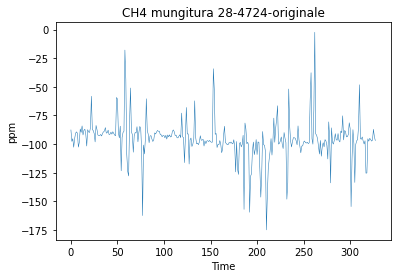

Milking mean is:  -54.87781335522762
Milking median is:  -79.3493320008084
Milking std. deviation is 125.81
treshold is std x3:  377.43


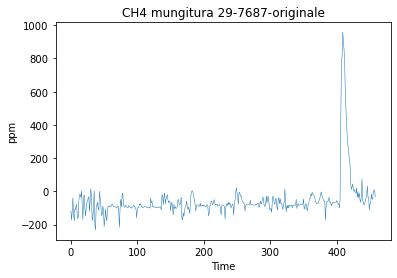

Milking mean is:  -76.25343517401576
Milking median is:  -79.67835025363794
Milking std. deviation is 24.35
treshold is std x3:  73.05000000000001


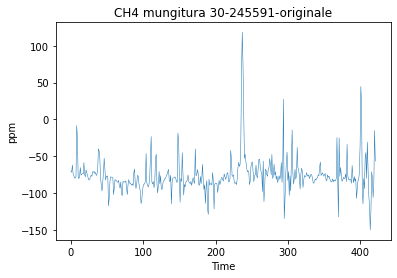

In [7]:
#DO NOT SAVE, save in the next cell

#dividing and plotting each milking (keeping animal information)

#inspection of milking with calculus of mean, median, standard deviation without removal of data

animals = list(set(mandria_ch4['Numero animale']))
mungiture = list(set(mandria_ch4['milking_number']))
#print(len(animals))
#print(len(mungiture))
    
for mungitura in mungiture[0:30]:
    milking_ch4 = mandria_ch4[mandria_ch4['milking_number'] == mungitura]
    milking_ch4 = milking_ch4.reset_index(drop=True)
    #print(milking_ch4.head())
    
    buffalo = milking_ch4.iloc[0,2]
    
    ch4 = milking_ch4
    
    milking_mean = ch4['CH4'].mean()
    print ("Milking mean is: ", milking_mean)
    milking_median = ch4['CH4'].median()
    print("Milking median is: ", milking_median)
    std = np.std(ch4['CH4'])
    print('Milking std. deviation is', round(std, 2)) 
    threshold = round(std, 2)*3
    print('treshold is std x3: ', threshold)
    
    #Plot singole mungiture 
    plt.figure(facecolor='white')
    plt.xlabel('Time')
    plt.ylabel('ppm')
    title = "CH4 mungitura " + str(mungitura) + "-" + str(buffalo) + "-originale"
    plt.title(title)
    plt.plot(milking_ch4['CH4'], linewidth=0.5)
    
    '''
    directory = "./plot_bufale/mungiture/"
    if not os.path.exists(directory):
        os.makedirs(directory)
    file_path = directory + str(mungitura) + "_originale.png"
    plt.savefig(file_path, format="png", dpi=200)
    '''
    
    plt.show()

In [ ]:
#In order to proceede with outliers removal with 3-sigma method,
#check that data are normally distributed

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


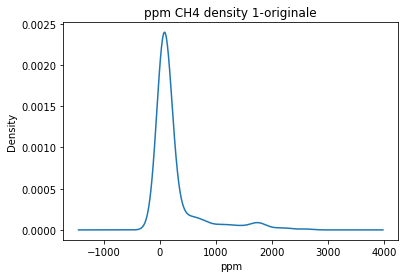

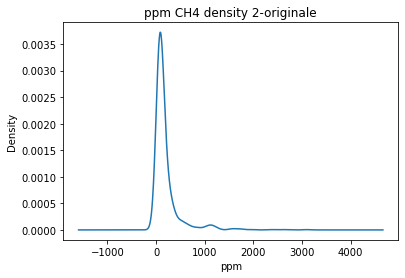

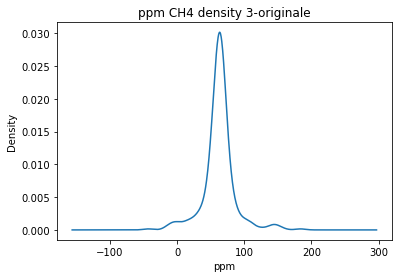

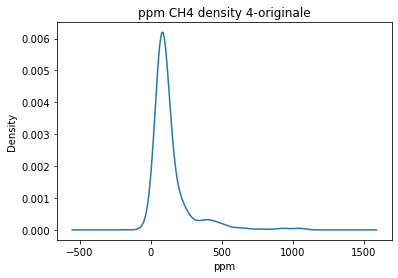

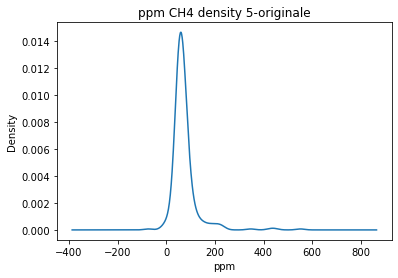

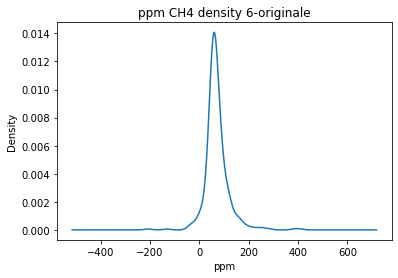

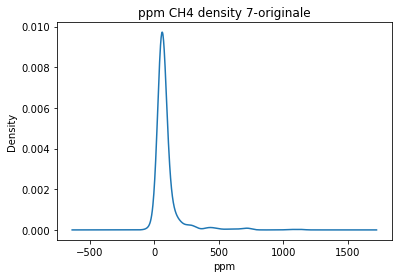

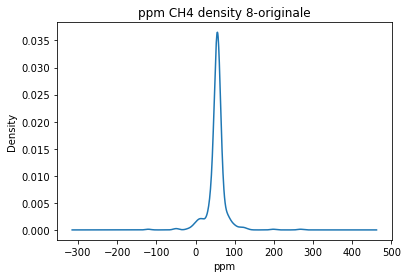

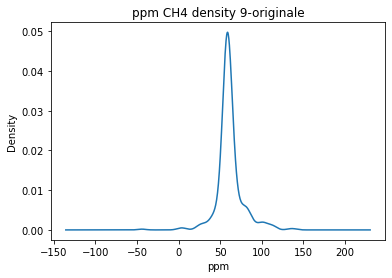

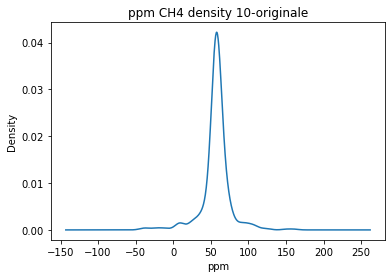

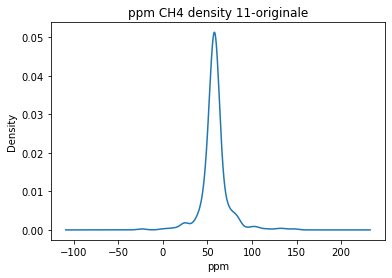

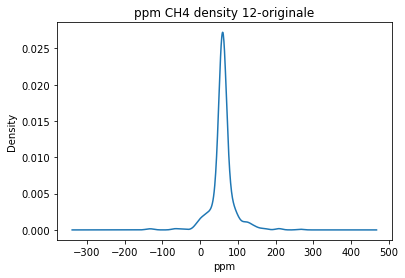

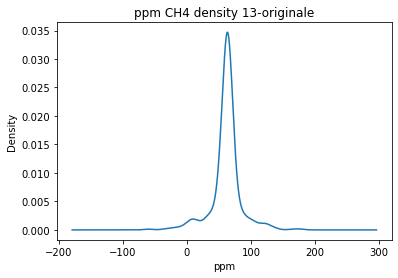

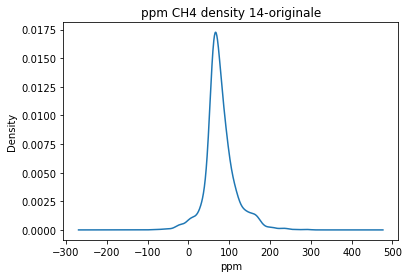

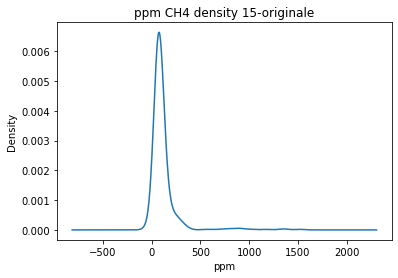

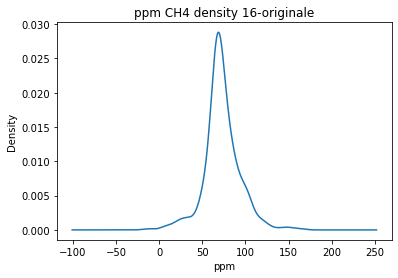

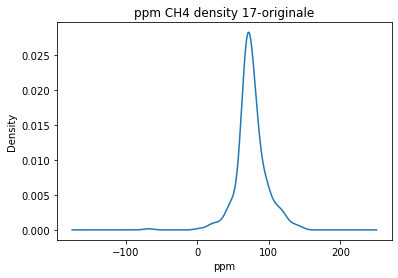

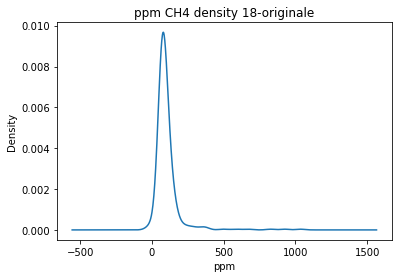

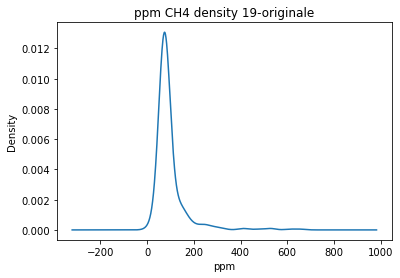

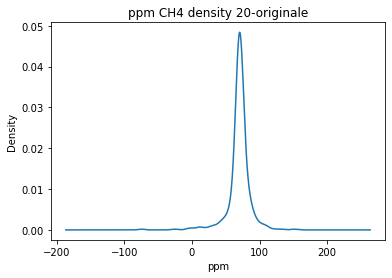

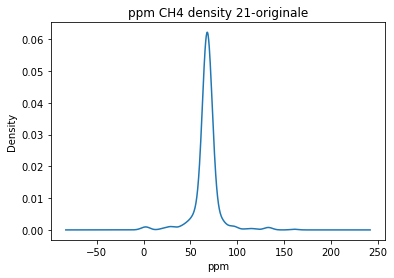

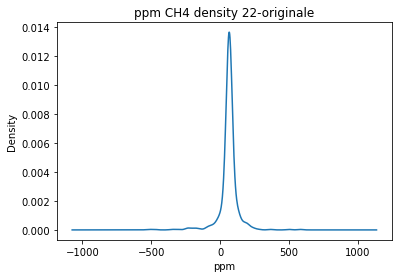

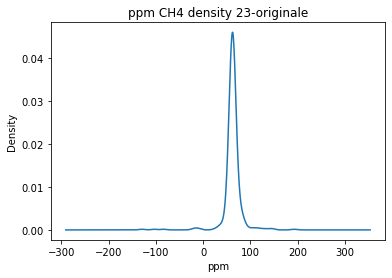

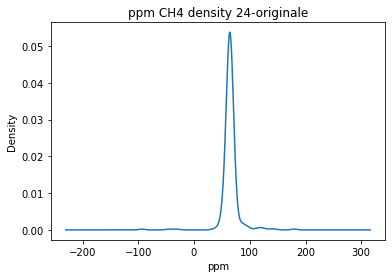

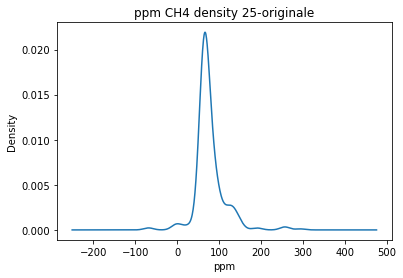

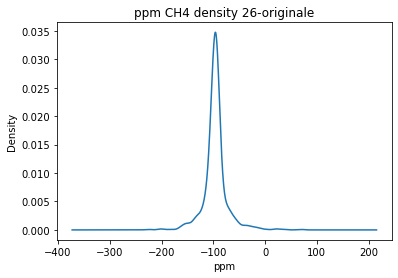

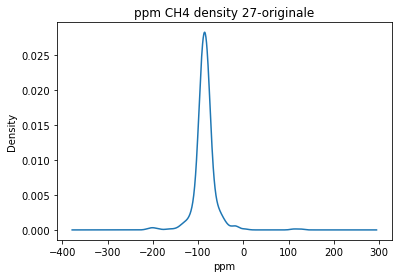

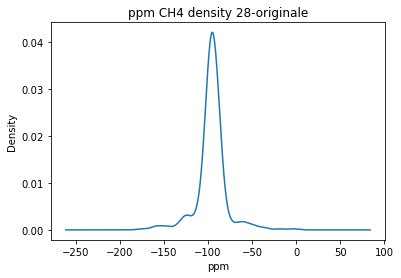

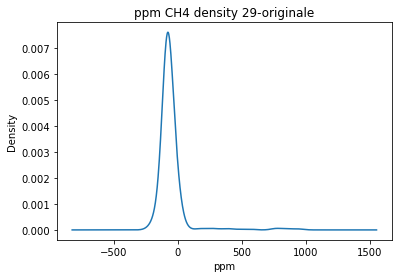

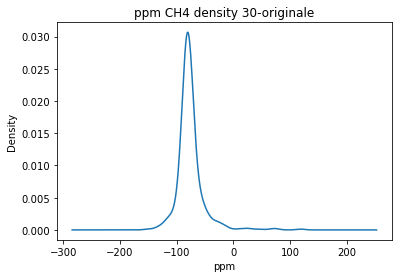

In [8]:
#dividing and plotting density plot of each milking 

animals = list(set(mandria_ch4['Numero animale']))
mungiture = list(set(mandria_ch4['milking_number']))
    
for mungitura in mungiture[0:30]:
    milking_ch4 = mandria_ch4[mandria_ch4['milking_number'] == mungitura]
    milking_ch4 = milking_ch4.reset_index(drop=True)
    
    buffalo = milking_ch4.iloc[0,2]
    
    ch4 = milking_ch4
    series = pd.Series(ch4['CH4'])
    #Plot individual milking density distribution
    plt.xlabel('ppm')
    plt.ylabel('Density')
    title = "ppm CH4 density " + str(mungitura) + "-originale"
    plt.title(title)
    series.plot.kde()
    plt.show()  


    '''
    directory = "./plot_bufale/mungiture/"
    if not os.path.exists(directory):
        os.makedirs(directory)
    file_path = directory + "_density_" str(mungitura) + "_originale.png"
    #plt.savefig(file_path, format="png", dpi=250)
    '''

In [ ]:
#Removal of background 5 points and outliers

In [ ]:
#inspection of milking and removal of background (5 minimum points) and outliers
#with calculus of mean, median, standard deviation

animals = list(set(mandria_ch4['Numero animale']))
mungiture = list(set(mandria_ch4['milking_number']))
#print(len(animals))
#print(len(mungiture))
    
for mungitura in mungiture[0:30]:
    milking_ch4 = mandria_ch4[mandria_ch4['milking_number'] == mungitura]
    milking_ch4 = milking_ch4.reset_index(drop=True)
    #print(milking_ch4.head())
    
    buffalo = milking_ch4.iloc[0,2]
    
    milking_mean = milking_ch4['CH4'].mean()
    print ("Milking mean is: ", milking_mean)
        
    #Calculus of background of each milking with minimum of 5 points
    
    minim = list()    
    ch4 = milking_ch4    
    #print(ch4.shape)
    for time in range(5):
        minimum = ch4['CH4'].min()
        minim.append(minimum)
        ch4 = ch4[ch4['CH4'] != minimum] #this way we cut that 5 data, but do not remove from all the data
        
    #print(ch4.shape)
    
    minim = pd.Series(minim)
    background = minim.mean()
    print ("Average minimum background is: ", background)
    
    ch4_no_back = milking_ch4
    ch4_no_back['CH4'] = ch4_no_back['CH4'].apply(lambda x: x - background)
    
    #check that the dataframe with which we calculate the minimum is smaller than the original
    #and most important that the original and tha no_back dataframe contains all the data, including all the minimums
    
    #print(ch4.shape)
    #print(milking_ch4.shape)
    #print(ch4_no_back.shape)
    
    no_back_mean = ch4_no_back['CH4'].mean()
    print("Average after removal of background is: ", no_back_mean)
    
    #print(ch4.shape)
    
    #milking_median = ch4['CH4'].median()
    #print("Milking median is: ", milking_median)
    std = np.std(ch4_no_back['CH4'])
    print('Milking std. deviation is', round(std, 2)) 
    threshold = round(round(std, 2)*3,2)
    print('treshold is std x3: ', threshold)
    
    positive_outliers = round(no_back_mean + threshold, 2)
    negative_outliers = round(no_back_mean - threshold, 2)
    #print(positive_outliers, negative_outliers)    
    
    #print(ch4.shape)
    filtered_milking_ch4 = ch4_no_back[ch4_no_back['CH4'] <= positive_outliers]
    filtered_milking_ch4 = filtered_milking_ch4[filtered_milking_ch4['CH4'] >= negative_outliers]
    
    #print(filtered_milking_ch4.shape)
    
    no_back_no_out_median = filtered_milking_ch4['CH4'].median()
    print("Median after removal of background and outliers is: ", no_back_no_out_median)
    
    #Plot singole mungiture filtrate per outliers e background
    plt.figure(facecolor='white')
    plt.xlabel('Time')
    plt.ylabel('ppm without background')
    title = "CH4 " + str(mungitura) + "-" + str(buffalo) + "-w/o-background-5"
    plt.title(title)
    plt.plot(filtered_milking_ch4['CH4'], linewidth=0.5, color = "red")
    '''
    directory = "./plot_bufale/mungiture/"
    if not os.path.exists(directory):
        os.makedirs(directory)
    file_path = directory + str(mungitura) + "_filtered_background_5_outlier.png"
    plt.savefig(file_path, format="png", dpi=250)
    '''
    
    plt.show()

In [ ]:
#Removal background 10 points and outliers

In [ ]:
#inspection of milking with calculus of mean, median, standard deviation and removal of background (10 minimum points)

animals = list(set(mandria_ch4['Numero animale']))
mungiture = list(set(mandria_ch4['milking_number']))
#print(len(animals))
#print(len(mungiture))
    
for mungitura in mungiture[-20:-1]:
    milking_ch4 = mandria_ch4[mandria_ch4['milking_number'] == mungitura]
    milking_ch4 = milking_ch4.reset_index(drop=True)
    #print(milking_ch4.head())
    
    buffalo = milking_ch4.iloc[0,2]
    
    milking_mean = milking_ch4['CH4'].mean()
    print ("Milking mean is: ", milking_mean)
        
    #Calculus of background of each milking with minimum of 5 points
    #ch4 = pd.DataFrame(milking_ch4['CH4'])
    
    minim = list()    
    ch4 = milking_ch4    
    #print(ch4.shape)
    for time in range(10):
        minimum = ch4['CH4'].min()
        minim.append(minimum)
        ch4 = ch4[ch4['CH4'] != minimum] #this way we cut that 5 data, but do not remove from all the data
        
    #print(ch4.shape)
    
    minim = pd.Series(minim)
    background = minim.mean()
    print ("Average minimum background is: ", background)
    
    ch4_no_back = milking_ch4
    ch4_no_back['CH4'] = ch4_no_back['CH4'].apply(lambda x: x - background)
    
    #check that the dataframe with which we calculate the minimum is smaller than the original
    #and most important that the original and tha no_back dataframe contains all the data, including all the minimums
    
    #print(ch4.shape)
    #print(milking_ch4.shape)
    #print(ch4_no_back.shape)
    
    no_back_mean = ch4_no_back['CH4'].mean()
    print("Average after removal of background is: ", no_back_mean)
        
    #milking_median = ch4['CH4'].median()
    #print("Milking median is: ", milking_median)
    std = np.std(ch4_no_back['CH4'])
    print('Milking std. deviation is', round(std, 2)) 
    threshold = round(round(std, 2)*3,2)
    print('treshold is std x3: ', threshold)
    
    positive_outliers = round(no_back_mean + threshold, 2)
    negative_outliers = round(no_back_mean - threshold, 2)
    #print(positive_outliers, negative_outliers)    
    
    #print(ch4.shape)
    filtered_milking_ch4 = ch4_no_back[ch4_no_back['CH4'] <= positive_outliers]
    filtered_milking_ch4 = filtered_milking_ch4[filtered_milking_ch4['CH4'] >= negative_outliers]
    
    #print(filtered_milking_ch4.shape)
    
    no_back_no_out_median = filtered_milking_ch4['CH4'].median()
    print("Median after removal of background and outliers is: ", no_back_no_out_median)
    
    #Plot singole mungiture filtrate per outliers e background
    plt.figure(facecolor='white')
    plt.xlabel('Time')
    plt.ylabel('ppm without background')
    title = "CH4 " + str(mungitura) + "-" + str(buffalo) + "-w/o-background-10"
    plt.title(title)
    plt.plot(filtered_milking_ch4['CH4'], linewidth=0.5, color = "red")
    
    
    directory = "./plot_bufale/mungiture/"
    if not os.path.exists(directory):
        os.makedirs(directory)
    file_path = directory + str(mungitura) + "_filtered_background_10_outlier.png"
    plt.savefig(file_path, format="png", dpi=200)
    
    
    plt.show()

In [ ]:
#Inverse order outlier-background

(541, 4)
(536, 4)
Average after removal of background is:  231.41
Median after removal of background is:  135.71
1


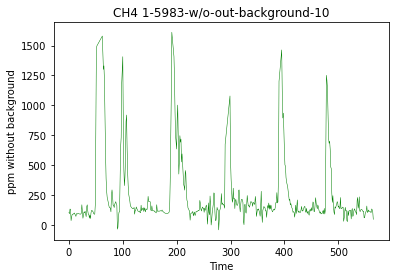

(910, 4)
(905, 4)
Average after removal of background is:  148.61
Median after removal of background is:  95.63
2


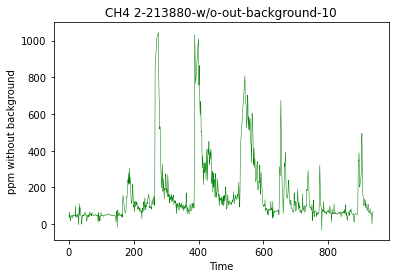

(335, 4)
(329, 4)
Average after removal of background is:  60.14
Median after removal of background is:  60.8
3


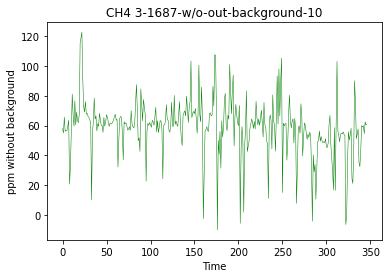

(350, 4)
(346, 4)
Average after removal of background is:  110.37
Median after removal of background is:  74.45
4


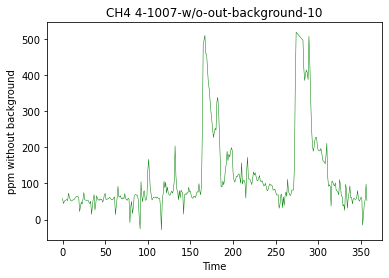

(315, 4)
(312, 4)
Average after removal of background is:  72.38
Median after removal of background is:  65.03
5


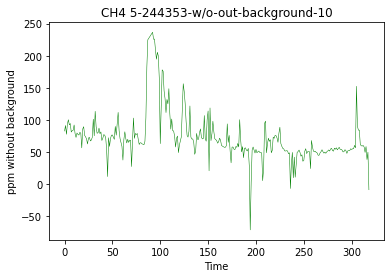

(405, 4)
(399, 4)
Average after removal of background is:  91.52
Median after removal of background is:  84.03
6


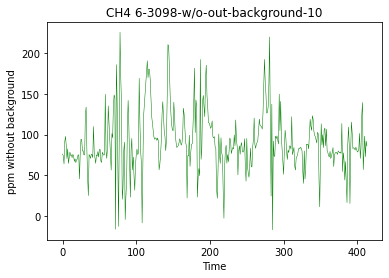

(536, 4)
(531, 4)
Average after removal of background is:  82.65
Median after removal of background is:  66.67
7


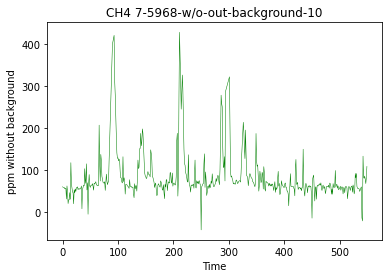

(443, 4)
(438, 4)
Average after removal of background is:  56.13
Median after removal of background is:  56.85
8


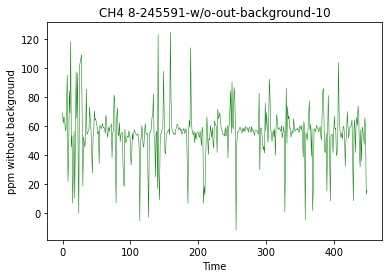

(420, 4)
(415, 4)
Average after removal of background is:  33.27
Median after removal of background is:  31.0
9


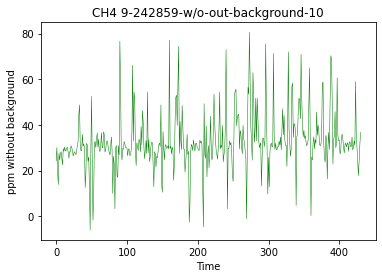

(442, 4)
(436, 4)
Average after removal of background is:  49.68
Median after removal of background is:  49.03
10


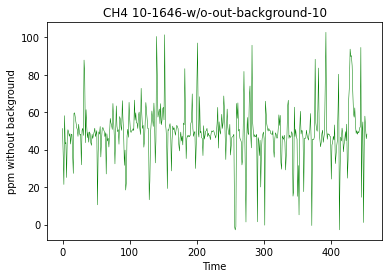

(315, 4)
(310, 4)
Average after removal of background is:  33.05
Median after removal of background is:  32.59
11


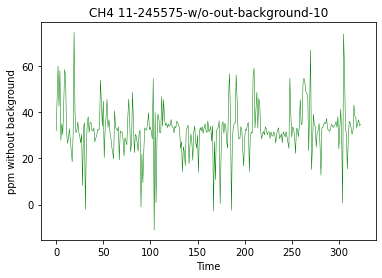

(486, 4)
(482, 4)
Average after removal of background is:  66.27
Median after removal of background is:  65.58
12


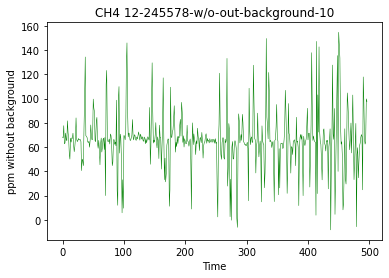

(427, 4)
(422, 4)
Average after removal of background is:  60.01
Median after removal of background is:  60.19
13


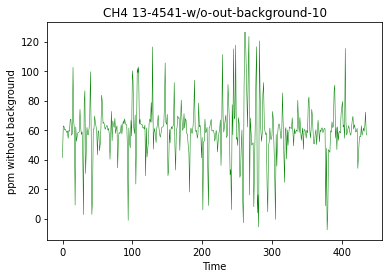

(1118, 4)
(1113, 4)
Average after removal of background is:  100.89
Median after removal of background is:  95.5
14


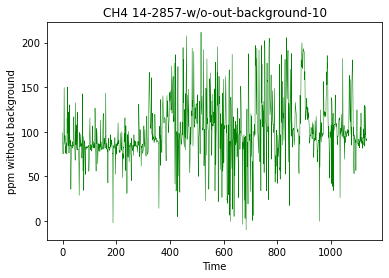

(441, 4)
(435, 4)
Average after removal of background is:  97.74
Median after removal of background is:  76.0
15


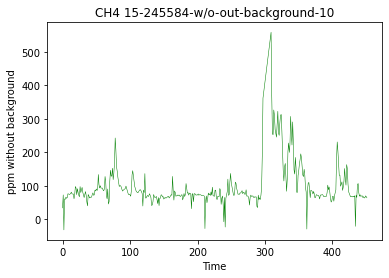

(388, 4)
(383, 4)
Average after removal of background is:  51.47
Median after removal of background is:  48.43
16


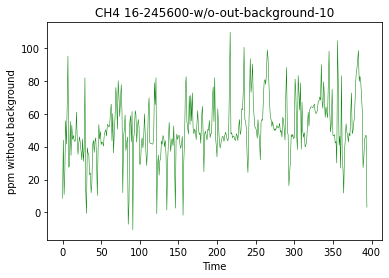

(364, 4)
(359, 4)
Average after removal of background is:  50.37
Median after removal of background is:  47.24
17


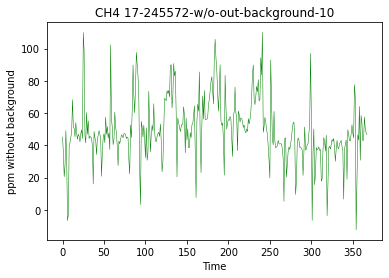

(366, 4)
(361, 4)
Average after removal of background is:  86.71
Median after removal of background is:  69.97
18


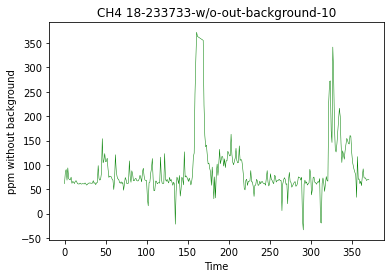

(374, 4)
(371, 4)
Average after removal of background is:  60.47
Median after removal of background is:  46.75
19


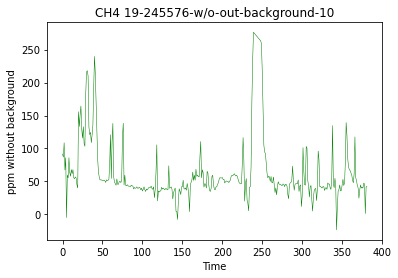

(442, 4)
(436, 4)
Average after removal of background is:  39.45
Median after removal of background is:  38.58
20


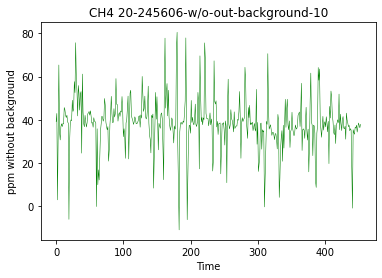

(443, 4)
(438, 4)
Average after removal of background is:  32.52
Median after removal of background is:  32.44
21


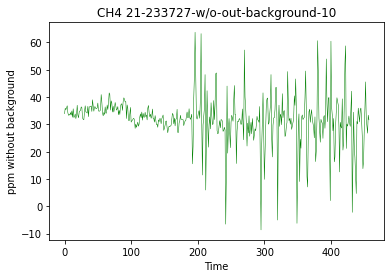

(606, 4)
(602, 4)
Average after removal of background is:  155.05
Median after removal of background is:  152.5
22


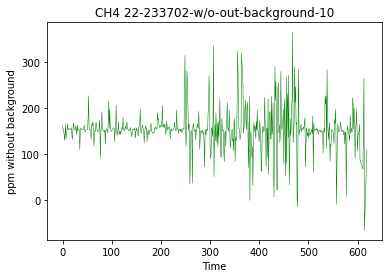

(412, 4)
(408, 4)
Average after removal of background is:  26.72
Median after removal of background is:  25.4
23


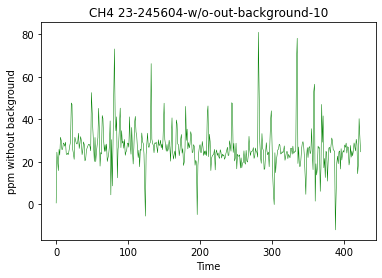

(328, 4)
(325, 4)
Average after removal of background is:  17.55
Median after removal of background is:  17.05
24


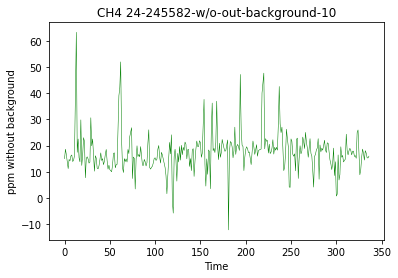

(306, 4)
(300, 4)
Average after removal of background is:  66.61
Median after removal of background is:  57.42
25


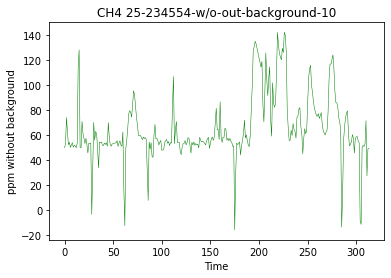

(734, 4)
(730, 4)
Average after removal of background is:  61.65
Median after removal of background is:  62.24
26


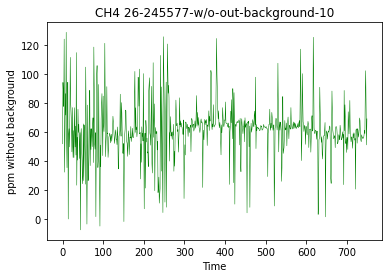

(455, 4)
(451, 4)
Average after removal of background is:  49.76
Median after removal of background is:  48.54
27


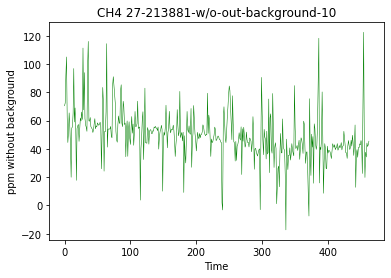

(319, 4)
(316, 4)
Average after removal of background is:  39.9
Median after removal of background is:  39.58
28


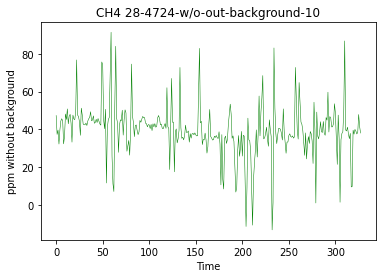

(449, 4)
(445, 4)
Average after removal of background is:  120.38
Median after removal of background is:  110.65
29


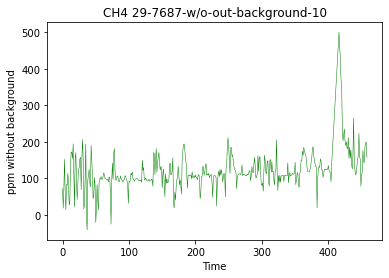

(414, 4)
(410, 4)
Average after removal of background is:  45.09
Median after removal of background is:  43.14
30


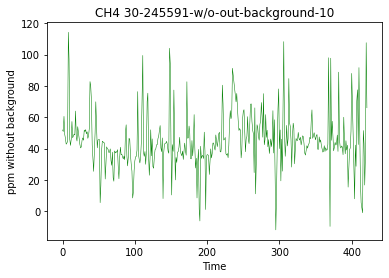

(622, 4)
(616, 4)
Average after removal of background is:  57.79
Median after removal of background is:  56.24
31


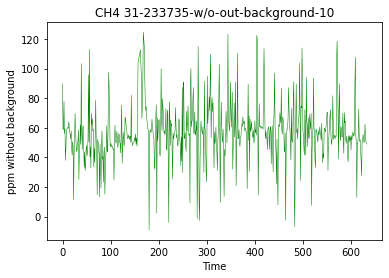

(739, 4)
(734, 4)
Average after removal of background is:  71.2
Median after removal of background is:  63.08
32


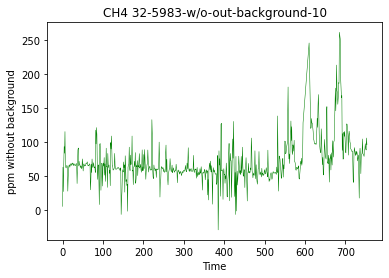

(350, 4)
(346, 4)
Average after removal of background is:  56.55
Median after removal of background is:  49.92
33


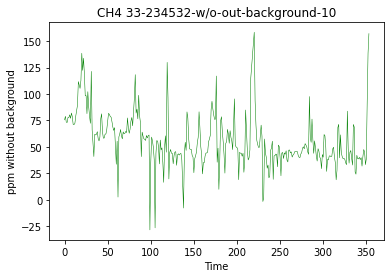

(301, 4)
(297, 4)
Average after removal of background is:  49.22
Median after removal of background is:  38.04
34


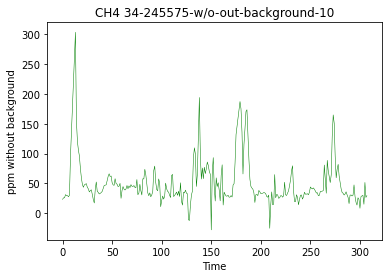

(663, 4)
(660, 4)
Average after removal of background is:  127.38
Median after removal of background is:  125.86
35


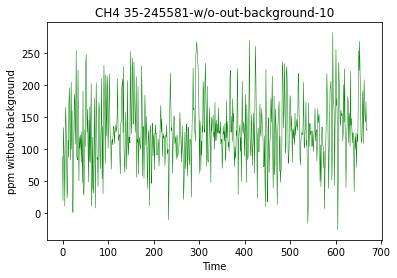

(835, 4)
(831, 4)
Average after removal of background is:  84.07
Median after removal of background is:  75.41
36


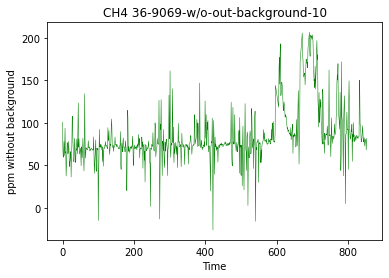

(371, 4)
(368, 4)
Average after removal of background is:  86.38
Median after removal of background is:  59.75
37


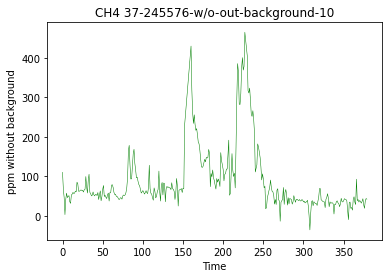

(305, 4)
(301, 4)
Average after removal of background is:  71.0
Median after removal of background is:  62.98
38


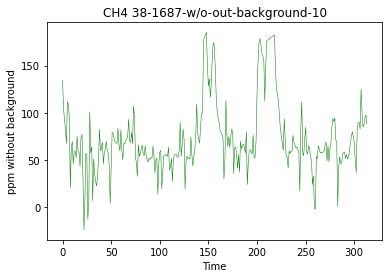

(987, 4)
(981, 4)
Average after removal of background is:  59.27
Median after removal of background is:  59.03
39


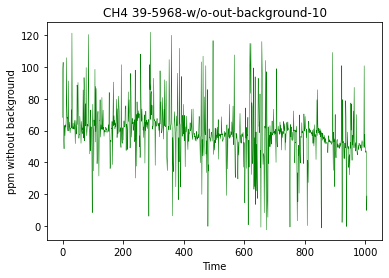

(931, 4)
(926, 4)
Average after removal of background is:  94.27
Median after removal of background is:  85.57
40


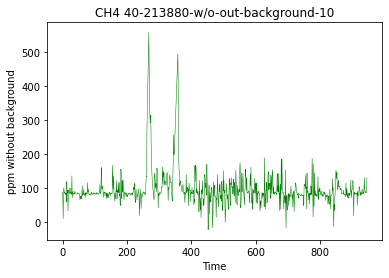

(487, 4)
(481, 4)
Average after removal of background is:  103.47
Median after removal of background is:  77.39
41


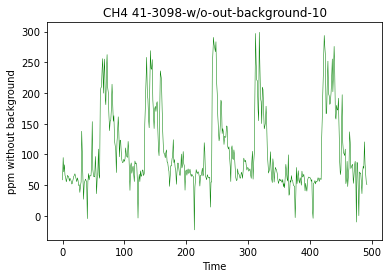

(408, 4)
(405, 4)
Average after removal of background is:  48.29
Median after removal of background is:  46.87
42


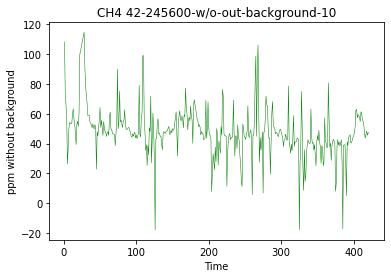

(440, 4)
(436, 4)
Average after removal of background is:  68.76
Median after removal of background is:  55.57
43


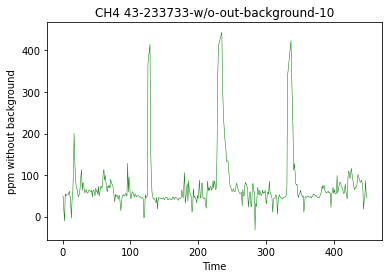

(363, 4)
(358, 4)
Average after removal of background is:  76.0
Median after removal of background is:  55.17
44


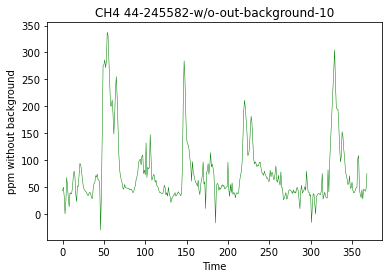

(388, 4)
(384, 4)
Average after removal of background is:  134.23
Median after removal of background is:  112.92
45


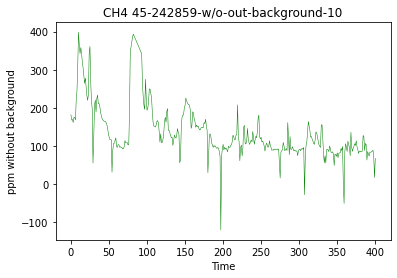

(555, 4)
(551, 4)
Average after removal of background is:  118.49
Median after removal of background is:  102.61
46


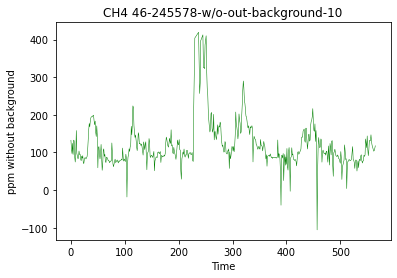

(995, 4)
(991, 4)
Average after removal of background is:  160.52
Median after removal of background is:  141.19
47


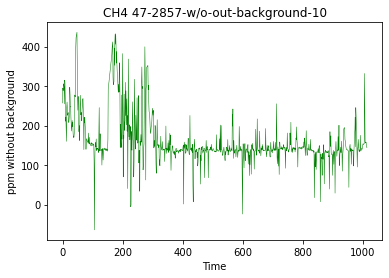

(507, 4)
(501, 4)
Average after removal of background is:  81.91
Median after removal of background is:  75.12
48


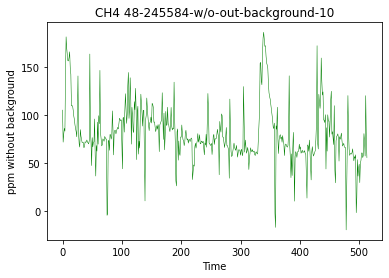

(513, 4)
(509, 4)
Average after removal of background is:  87.22
Median after removal of background is:  79.44
49


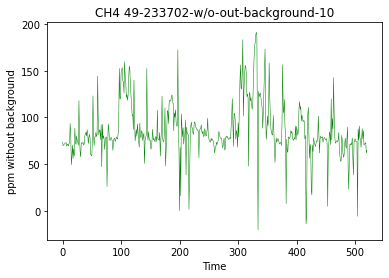

(662, 4)
(657, 4)
Average after removal of background is:  105.72
Median after removal of background is:  94.86
50


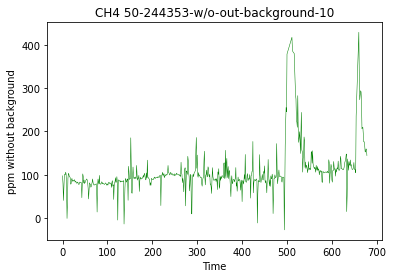

Mean of all milkings is:  78.7916224836053
Mean of all medians is:  68.12051757148869


'\n#Save in a dataframe means for milkings\nmeans_df = pd.DataFrame()\nmilkings = list(mandria_ch4[\'milking_number\'].unique())\nmeans_df[\'milking_number\'] = milkings\nmeans_df[\'means\'] = means\nmeans_df[\'medians\'] = medians\nmeans_df[\'animal\'] = buffaloes\nmeans_df.loc[0, \'final_mean\'] = final_mean\nmeans_df.loc[0, \'final_medians\'] = final_medians\nmeans_df.to_excel("./means_milkings_may.xlsx")\n\n\nprint(means_df.head())\n'

In [9]:
#inspection of milking removal of outliers (first) and background (after) (10 minimum points)

animals = list(set(mandria_ch4['Numero animale']))
mungiture = list(set(mandria_ch4['milking_number']))
#print(len(animals))
#print(len(mungiture))
    
means = list()
medians = list()
buffaloes = list()
    
for mungitura in mungiture[0:50]:
    milking_ch4 = mandria_ch4[mandria_ch4['milking_number'] == mungitura]
    milking_ch4 = milking_ch4.reset_index(drop=True)
    #print(milking_ch4.head())
    
    buffalo = milking_ch4.iloc[0,2]
    buffaloes.append(buffalo)
    
    milking_mean = milking_ch4['CH4'].mean()
    #print ("Milking mean is: ", milking_mean)
        
    std = np.std(milking_ch4['CH4'])
    #print('Milking std. deviation is', round(std, 2)) 
    threshold = round(round(std, 2)*3,2)
    #print('treshold is std x3: ', threshold)
    
    positive_outliers = round(milking_mean + threshold, 2)
    negative_outliers = round(milking_mean - threshold, 2)
    #print(positive_outliers, negative_outliers)    
    
    #print(ch4.shape)
    filtered_milking_ch4 = milking_ch4[milking_ch4['CH4'] <= positive_outliers]
    filtered_milking_ch4 = filtered_milking_ch4[filtered_milking_ch4['CH4'] >= negative_outliers]
    
    #print(milking_ch4.shape)
    #print(filtered_milking_ch4.shape)
    
    
    #Calculus of background of each milking with minimum of 5 points
    
    minim = list()    
    ch4 = filtered_milking_ch4    
    #print(ch4.shape)
    for time in range(10):
        minimum = ch4['CH4'].min()
        minim.append(minimum)
        ch4 = ch4[ch4['CH4'] != minimum] #this way we cut that 5 data, but do not remove from all the data
        
    #print(ch4.shape)
    
    minim = pd.Series(minim)
    background = minim.mean()
    #print ("Average minimum background is: ", round(background,2))
    
    ch4_no_back = filtered_milking_ch4
    ch4_no_back['CH4'] = ch4_no_back['CH4'].apply(lambda x: x - background)
    print(ch4_no_back.shape)
    
    #Remove negative data after removal of background
    ch4_no_back_no_neg = ch4_no_back[ch4_no_back['CH4'] > 0]
    #print(ch4_no_back_no_neg.head())
    print(ch4_no_back_no_neg.shape)

    
    #check that the dataframe with which we calculate the minimum is smaller than the original
    #and most important that the original and tha no_back dataframe contains all the data, including all the minimums
    
    #print(ch4.shape)
    #print(milking_ch4.shape)
    
    no_back_mean = ch4_no_back_no_neg['CH4'].mean()
    print("Average after removal of background is: ", round(no_back_mean,2))
    
    means.append(no_back_mean)
    
    no_back_median = ch4_no_back_no_neg['CH4'].median()
    print("Median after removal of background is: ", round(no_back_median,2))
    
    medians.append(no_back_median)
    #print(ch4.shape)
    
    print(str(mungitura))
    
    
    #Plot singole mungiture filtrate per outliers e background
    plt.figure(facecolor='white')
    plt.xlabel('Time')
    plt.ylabel('ppm without background')
    title = "CH4 " + str(mungitura) + "-" + str(buffalo) + "-w/o-out-background-10"
    plt.title(title)
    plt.plot(filtered_milking_ch4['CH4'], linewidth=0.5, color = "green")
    
    #no_back_no_out_mean = filtered_milking_ch4['CH4'].mean()
    #print("Average after removal of background and outliers is: ", no_back_no_out_mean)    
    '''
    directory = "./plot_bufale/mungiture/"
    if not os.path.exists(directory):
        os.makedirs(directory)
    file_path = directory + str(mungitura) + "_filtered_outlier_background_10.png"
    plt.savefig(file_path, format="png", dpi=200)
    '''
    plt.show()


#Calcolo media delle medie e delle mediane di tutte le mungiture dopo aver tolto outlier e background

means = pd.Series(means)
final_mean = means.mean()
print("Mean of all milkings is: ", final_mean)



medians = pd.Series(medians)
final_medians = medians.mean()
print("Mean of all medians is: ", final_medians)

'''
#Save in a dataframe means for milkings
means_df = pd.DataFrame()
milkings = list(mandria_ch4['milking_number'].unique())
means_df['milking_number'] = milkings
means_df['means'] = means
means_df['medians'] = medians
means_df['animal'] = buffaloes
means_df.loc[0, 'final_mean'] = final_mean
means_df.loc[0, 'final_medians'] = final_medians
means_df.to_excel("./means_milkings_may.xlsx")


print(means_df.head())
'''